# <center>**Lottery Number Patterns and Randomness**

### Project Overview

Explored historical New York lottery winning numbers for Mega Millions (2002–2024), Powerball (2010–2024), and Pick 10 (1987–2024) to investigate number frequency patterns, identify "hot" and "cold" numbers, and assess whether observed differences are consistent with random variation.

## **Data Preparation and Exploration**

In [1]:
# Import packages, ignore warnings, and show charts inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare

from matplotlib.patches import Patch

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

In [2]:
# Load lottery datasets

mega = pd.read_csv("MegaMillions.csv")
powerball = pd.read_csv("Powerball.csv")
pick10 = pd.read_csv("Pick10.csv")

# Show the first few rows
display(mega.head(5))
display(powerball.head(5))
display(pick10.head(5))

# Check dataset sizes
print("Mega Millions:", mega.shape)
print("Powerball:", powerball.shape)
print("Pick 10:", pick10.shape)

,Draw Date,Winning Numbers,Mega Ball,Multiplier
0,04/16/2024,21 26 36 44 59,2,4.0
1,04/12/2024,01 12 14 18 66,16,2.0
2,04/09/2024,34 43 51 52 69,25,4.0
3,04/05/2024,20 30 54 63 65,14,3.0
4,04/02/2024,10 50 56 60 66,19,3.0


,Draw Date,Winning Numbers,Multiplier
0,04/20/2024,04 35 41 44 58 25,3.0
1,04/17/2024,24 29 44 47 54 02,2.0
2,04/15/2024,07 16 41 56 61 23,3.0
3,04/13/2024,07 33 40 43 69 10,5.0
4,04/10/2024,06 07 12 24 36 15,2.0


,Draw Date,Winning Numbers
0,04/20/2024,01 08 17 18 34 35 39 41 42 44 48 52 58 60 61 6...
1,04/19/2024,01 03 05 10 14 16 21 27 32 36 39 42 49 54 60 6...
2,04/18/2024,05 07 19 21 25 32 34 37 39 42 48 58 59 63 66 6...
3,04/17/2024,01 07 10 14 15 17 20 21 23 26 29 53 55 57 58 6...
4,04/16/2024,01 05 07 10 12 14 33 39 43 46 50 52 55 63 65 6...


Mega Millions: (2285, 4)
Powerball: (1617, 3)
Pick 10: (13570, 2)


In [3]:
# Check data types, missing values, and duplicates

for name, df in {
    "Mega Millions": mega,
    "Powerball": powerball,
    "Pick 10": pick10}.items():
    print(f"\n{name}")
    display(pd.DataFrame({
        "Data Type": df.dtypes,
        "Missing Values": df.isnull().sum()}))
    print("Duplicate Rows:", df.duplicated().sum())


Mega Millions


,Data Type,Missing Values
Draw Date,object,0
Winning Numbers,object,0
Mega Ball,int64,0
Multiplier,float64,903


Duplicate Rows: 0

Powerball


,Data Type,Missing Values
Draw Date,object,0
Winning Numbers,object,0
Multiplier,float64,210


Duplicate Rows: 0

Pick 10


,Data Type,Missing Values
Draw Date,object,0
Winning Numbers,object,0


Duplicate Rows: 0


In [4]:
# Convert Draw Date to a date type and add a Year column

for df in [mega, powerball, pick10]:
    df["Draw Date"] = pd.to_datetime(df["Draw Date"], format="%m/%d/%Y")
    df["Year"] = df["Draw Date"].dt.year

# Confirm the date range for each game
for name, df in {"Mega Millions": mega,
    "Powerball": powerball,
    "Pick 10": pick10}.items():
    print(f"{name}: {df['Draw Date'].min().date()} to {df['Draw Date'].max().date()}")

Mega Millions: 2002-05-17 to 2024-04-16
Powerball: 2010-02-03 to 2024-04-20
Pick 10: 1987-01-12 to 2024-04-20


In [5]:
# Split winning numbers into one row per number (main numbers only)

def split_main(df, game, n_main):
    nums = df["Winning Numbers"].str.split(expand=True).iloc[:, :n_main].astype(int)
    nums.columns = range(1, n_main + 1)
    nums["Draw Date"] = df["Draw Date"]
    nums["Year"] = df["Year"]
    long = nums.melt(id_vars=["Draw Date", "Year"], var_name="Position", value_name="Number")
    long["Game"] = game
    return long

main_numbers = pd.concat([
    split_main(mega, "Mega Millions", 5),
    split_main(powerball, "Powerball", 5),
    split_main(pick10, "Pick 10", 20)], ignore_index=True)

# Preview and confirm counts and number ranges by game
display(main_numbers.head())
display(main_numbers.groupby("Game")["Number"].agg(["count", "min", "max"]))

,Draw Date,Year,Position,Number,Game
0,2024-04-16,2024,1,21,Mega Millions
1,2024-04-12,2024,1,1,Mega Millions
2,2024-04-09,2024,1,34,Mega Millions
3,2024-04-05,2024,1,20,Mega Millions
4,2024-04-02,2024,1,10,Mega Millions


,count,min,max
Game,,,
Mega Millions,11425,1,75
Pick 10,271400,1,80
Powerball,8085,1,69


In [6]:
# Keep only drawings from each game's current number range

current = main_numbers[
    ((main_numbers["Game"] == "Mega Millions") & (main_numbers["Draw Date"] >= "2017-10-31")) |
    ((main_numbers["Game"] == "Powerball") & (main_numbers["Draw Date"] >= "2015-10-07")) |
    (main_numbers["Game"] == "Pick 10")].copy()

# Confirm drawings, numbers, and range for each game
display(current.groupby("Game").agg(
    Drawings=("Draw Date", "nunique"),
    Numbers=("Number", "count"),
    Min=("Number", "min"),
    Max=("Number", "max")))

,Drawings,Numbers,Min,Max
Game,,,,
Mega Millions,675,3375,1,70
Pick 10,13570,271400,1,80
Powerball,1026,5130,1,69


In [7]:
# Count how often each number was drawn and label hot and cold numbers

freq = (current.groupby(["Game", "Number"])
        .size()
        .reset_index(name="Count"))

# Expected count per number if every number were equally likely
draws = current.groupby("Game")["Draw Date"].nunique()
picks = {"Mega Millions": 5, "Powerball": 5, "Pick 10": 20}
pool = {"Mega Millions": 70, "Powerball": 69, "Pick 10": 80}

p = freq["Game"].map(lambda g: picks[g] / pool[g])
n = freq["Game"].map(draws)

freq["Expected"] = n * p
freq["Difference"] = freq["Count"] - freq["Expected"]

# Hot = 2+ standard deviations above expected, Cold = 2+ below
freq["Std Dev"] = np.sqrt(n * p * (1 - p))
freq["Z Score"] = freq["Difference"] / freq["Std Dev"]
freq["Status"] = np.select(
    [freq["Z Score"] >= 2, freq["Z Score"] <= -2],
    ["Hot", "Cold"],
    default="Normal")

# Summary by game
display(freq.groupby("Game").agg(
    Numbers=("Number", "count"),
    Expected=("Expected", "first"),
    Lowest=("Count", "min"),
    Highest=("Count", "max")))

# List the hot and cold numbers
display(freq[freq["Status"] != "Normal"].sort_values(["Game", "Z Score"], ascending=[True, False]))

,Numbers,Expected,Lowest,Highest
Game,,,,
Mega Millions,70,48.214286,34,64
Pick 10,80,3392.500000,3250,3541
Powerball,69,74.347826,55,97


,Game,Number,Count,Expected,Difference,Std Dev,Z Score,Status
9,Mega Millions,10,64,48.214286,15.785714,6.691069,2.359221,Hot
2,Mega Millions,3,63,48.214286,14.785714,6.691069,2.209769,Hot
48,Mega Millions,49,34,48.214286,-14.214286,6.691069,-2.124367,Cold
127,Pick 10,58,3541,3392.500000,148.500000,50.441798,2.943987,Hot
76,Pick 10,7,3286,3392.500000,-106.500000,50.441798,-2.111344,Cold
94,Pick 10,25,3250,3392.500000,-142.500000,50.441798,-2.825038,Cold
210,Powerball,61,97,74.347826,22.652174,8.304234,2.727786,Hot
170,Powerball,21,93,74.347826,18.652174,8.304234,2.246104,Hot
212,Powerball,63,92,74.347826,17.652174,8.304234,2.125684,Hot
162,Powerball,13,55,74.347826,-19.347826,8.304234,-2.329875,Cold


In [8]:
# Chi-square test: are the number frequencies consistent with a random drawing?

results = []
for game, df in freq.groupby("Game"):
    stat, p_value = chisquare(df["Count"], df["Expected"])
    results.append({
        "Game": game,
        "Chi-Square": round(stat, 2),
        "p-value": round(p_value, 4),
        "Result": "Seems Biased" if p_value < 0.05 else "Seems Random"})

display(pd.DataFrame(results))

,Game,Chi-Square,p-value,Result
0,Mega Millions,65.49,0.5974,Seems Random
1,Pick 10,60.68,0.9375,Seems Random
2,Powerball,70.45,0.3957,Seems Random


### Assessment - Data Preparation and Exploration Findings

**Datasets loaded**
- **Mega Millions:** 2,285 drawings from May 17, 2002, to April 16, 2024. Five main numbers per drawing, plus a separate Mega Ball and Multiplier column.
- **Powerball:** 1,617 drawings from February 3, 2010, to April 20, 2024. Six numbers per drawing stored together, with the Powerball as the sixth number, plus a Multiplier column.
- **Pick 10:** 13,570 drawings from January 12, 1987, to April 20, 2024. Twenty numbers per drawing.

**Data quality**
- No duplicate rows or repeated draw dates in any dataset.
- Every drawing had the correct count of numbers (5, 6, and 20), with no repeated main numbers within a drawing. Powerball's bonus number can match a main number because it comes from a separate pool.
- Multiplier values were missing for 903 Mega Millions drawings and 210 Powerball drawings. The multiplier is not used in this analysis, so these were left as-is.
- Draw dates were stored as text and converted to dates, and a Year column was added.

**Preparation**
- Winning numbers were stored as space-separated text and were split into one row per number, keeping the original columns unchanged.
- Only the main numbers were analyzed. The Mega Ball and Powerball are drawn from a separate, smaller pool and were excluded.
- Mega Millions and Powerball changed their number ranges during the period covered. Combining all years would make lower numbers look "hot" because they were eligible in more drawings. To keep the comparison fair, each game was limited to its current range:
  - **Mega Millions:** 1–70, from October 31, 2017 (675 drawings, 3,375 numbers)
  - **Powerball:** 1–69, from October 7, 2015 (1,026 drawings, 5,130 numbers)
  - **Pick 10:** 1–80, all years (13,570 drawings, 271,400 numbers)
- Pick 10 contributes far more numbers than the other two games, so each game was analyzed separately.

**Number frequencies**
- Every number in each game's range was drawn at least once.
- Expected count per number if every number were equally likely: about 48.2 (Mega Millions), 74.3 (Powerball), and 3,392.5 (Pick 10).
- Actual counts ranged from 34 to 64 (Mega Millions), 55 to 97 (Powerball), and 3,250 to 3,541 (Pick 10).

**Hot and cold numbers** (2 or more standard deviations from expected)
- **Mega Millions:** hot 3 and 10; cold 49
- **Powerball:** hot 21, 61, and 63; cold 13
- **Pick 10:** hot 58; cold 7 and 25
- About 5% of numbers are expected to cross this cutoff by chance alone, roughly 3 to 4 per game. Across all three games, 10 numbers were flagged, approximately the number expected by chance.

**Randomness test (chi-square)**
- All three games returned p-values well above 0.05 (Mega Millions 0.60, Powerball 0.40, Pick 10 0.94).
- The differences between numbers are consistent with random variation and provide no convincing evidence of bias in the drawings. However, the results do not prove that the lotteries are completely random.
- The standard chi-square test provides an approximate assessment because multiple numbers are selected without replacement in each drawing.


## **Data Visualization**

## VISUAL 1 - Donut Chart of Share of All Numbers Drawn by Game

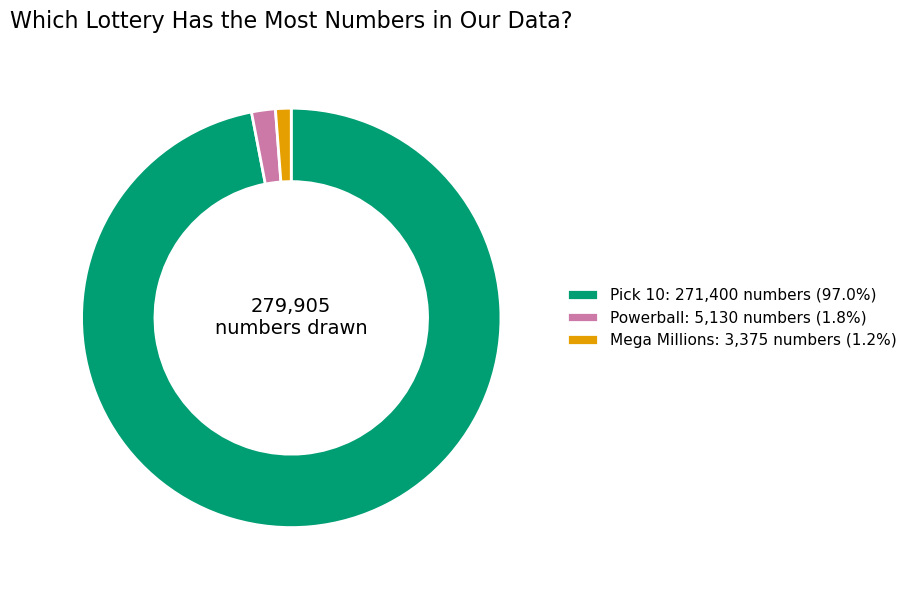

In [9]:
# Donut chart showing each game's share of all numbers drawn using colorblind palette

volume = current["Game"].value_counts().reindex(["Pick 10", "Powerball", "Mega Millions"])
share = volume / volume.sum() * 100
game_colors = {"Pick 10": "#009E73", "Powerball": "#CC79A7", "Mega Millions": "#E69F00"}

fig, ax = plt.subplots(figsize=(10, 6))
wedges, _ = ax.pie(volume, colors=[game_colors[g] for g in volume.index], startangle=90,
                   counterclock=False, wedgeprops=dict(width=0.35, edgecolor="white", linewidth=2))

# Legend with counts and percentages
labels = [f"{g}: {volume[g]:,} numbers ({share[g]:.1f}%)" for g in volume.index]
ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=11)

# Total in the center
ax.text(0, 0, f"{volume.sum():,}\nnumbers drawn", ha="center", va="center", fontsize=14)
ax.set_title("Which Lottery Has the Most Numbers in Our Data?", fontsize=16, pad=20)

plt.tight_layout()
plt.show()

### Assessment - Visual 1

- Pick 10 accounts for 97.0% (271,400) of the 279,905 main-number observations, compared with 1.8% (5,130) for Powerball and 1.2% (3,375) for Mega Millions.
- Pick 10's dominance reflects its longer historical coverage, greater number of drawings, and 20 numbers selected per drawing compared with five main numbers for the other games.
- Combining the three games without accounting for these differences would allow Pick 10 to overwhelm the results and potentially create misleading comparisons.
- This chart illustrates why each lottery is examined separately using its own number pool, drawing counts, and expected frequencies. The differences in data volume do not indicate that one lottery is more or less random than another.

## VISUAL 2 - Polar Wheel of Hot and Cold Numbers by Game

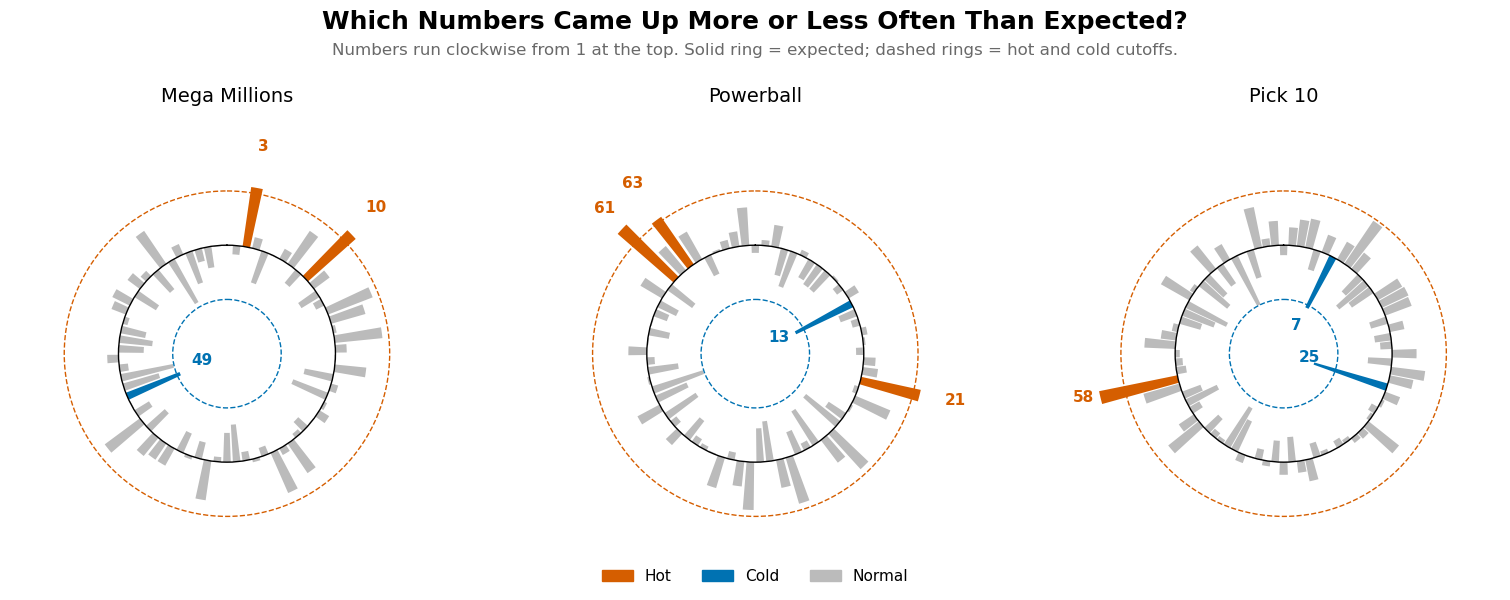

In [10]:
# Polar wheel per game: spokes show how far each number is from expected

colors = {"Hot": "#D55E00", "Cold": "#0072B2", "Normal": "#BBBBBB"}

fig, axes = plt.subplots(1, 3, figsize=(16, 6), subplot_kw={"projection": "polar"})

for ax, game in zip(axes, ["Mega Millions", "Powerball", "Pick 10"]):
    df = freq[freq["Game"] == game]
    angles = np.linspace(0, 2 * np.pi, len(df), endpoint=False)
    ax.bar(angles, df["Z Score"], bottom=4, width=0.07, color=df["Status"].map(colors))

    # Rings: expected (solid), hot and cold cutoffs (dashed)
    for r, c, ls in [(4, "black", "-"), (6, "#D55E00", "--"), (2, "#0072B2", "--")]:
        ax.axhline(r, color=c, linestyle=ls, linewidth=1)

    # Label hot numbers outside, cold numbers inside
    for a, num, status in zip(angles, df["Number"], df["Status"]):
        if status != "Normal":
            ax.text(a, 7.6 if status == "Hot" else 1, num, ha="center",
                    fontsize=11, fontweight="bold", color=colors[status])

    ax.set(theta_zero_location="N", theta_direction=-1, ylim=(0, 8), xticks=[], yticks=[])
    ax.spines["polar"].set_visible(False)
    ax.set_title(game, fontsize=14, pad=25)

fig.legend(handles=[Patch(color=c, label=s) for s, c in colors.items()],
           loc="lower center", ncol=3, frameon=False, fontsize=11, bbox_to_anchor=(0.5, 0))
fig.suptitle("Which Numbers Came Up More or Less Often Than Expected?", fontsize=18, fontweight="bold")
fig.text(0.5, 0.905, "Numbers run clockwise from 1 at the top. Solid ring = expected; dashed rings = hot and cold cutoffs.",
         ha="center", fontsize=12, color="dimgray")
plt.tight_layout(rect=[0, 0.02, 1, 0.86])
plt.show()

### Assessment - Visual 2

- **Hot numbers** appeared at least two standard deviations more frequently than expected, while **cold numbers** appeared at least two standard deviations less frequently than expected. These classifications describe historical results, not the likelihood of future drawings.
- Most numbers in all three lotteries stayed close to the expected ring, indicating that their frequencies were generally consistent with what a fair drawing would produce.
- Only 10 numbers crossed the hot or cold thresholds:
  - **Mega Millions:** Hot numbers were 3 and 10. Cold number was 49.
  - **Powerball:** Hot numbers were 21, 61, and 63. Cold number was 13.
  - **Pick 10:** Hot number was 58. Cold numbers were 7 and 25.
- The standout numbers were scattered around the wheels rather than concentrated in one section of the number ranges. No obvious grouping appeared across the three games.
- Overall, the wheels reinforce the earlier statistical findings. Although a few numbers appeared unusually often or rarely, most remained near their expected frequencies. These differences are consistent with random variation and do not provide convincing evidence of bias.


## VISUAL 3 - Swarm Plot of Distance from Expected by Game

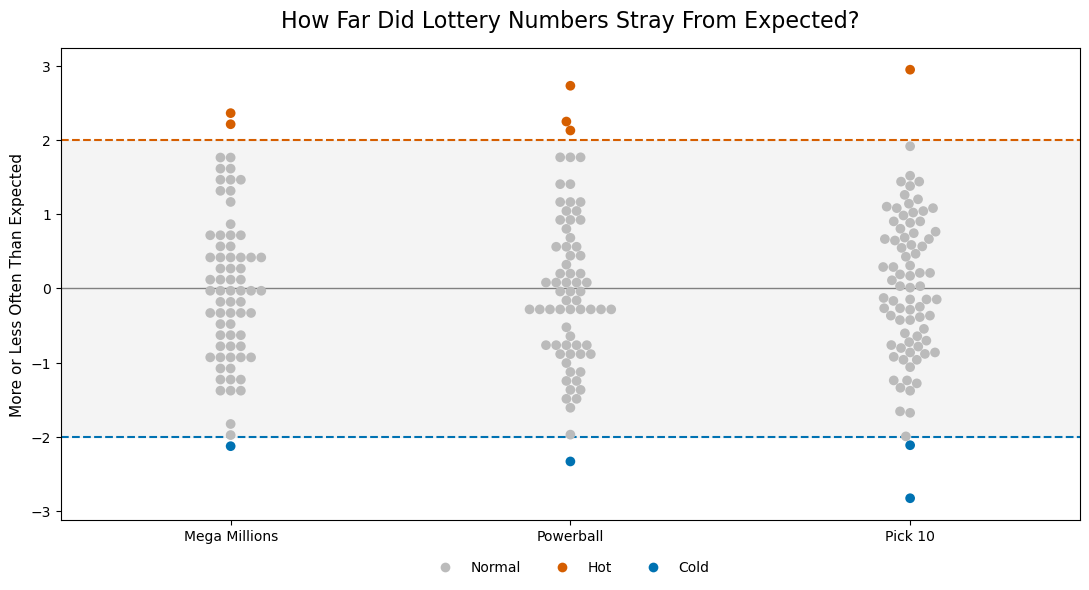

In [11]:
# Swarm plot showing how far lottery numbers varied from expected

colors = {"Hot": "#D55E00", "Cold": "#0072B2", "Normal": "#BBBBBB"}

fig, ax = plt.subplots(figsize=(11, 6))

# Shaded area shows the expected range
ax.axhspan(-2, 2, color="#BBBBBB", alpha=0.15)
ax.axhline(2, color="#D55E00", linestyle="--")
ax.axhline(-2, color="#0072B2", linestyle="--")
ax.axhline(0, color="gray", linewidth=1)

sns.swarmplot(data=freq, x="Game", y="Z Score", hue="Status",
              palette=colors, size=7, ax=ax,
              order=["Mega Millions", "Powerball", "Pick 10"])

ax.set_title("How Far Did Lottery Numbers Stray From Expected?", fontsize=16, pad=15)
ax.set_xlabel("")
ax.set_ylabel("More or Less Often Than Expected", fontsize=11)
ax.legend(title="", ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

### Assessment - Visual 3

- Each dot represents one number, and its height shows its **z-score**: how far that number's count was from the expected count, measured in standard deviations. A z-score of 0 means the number was drawn exactly as often as expected, positive values mean more often, and negative values mean less often. In a fair drawing, about 68% of numbers should fall between -1 and +1, and about 95% between -2 and +2. The results closely match this: 66.7% of the 219 numbers fell between -1 and +1, and 95.4% fell between -2 and +2. No number reached an extreme value of 4 or 5, which would warrant further investigation into possible bias. Z-scores ranged:
  - **Mega Millions:** -2.12 to +2.36
  - **Powerball:** -2.33 to +2.73
  - **Pick 10:** -2.83 to +2.94
- The dots were balanced above and below expected (105 above and 114 below), and all three games showed the same shape: crowded near zero and thinning toward the edges.
- All 10 hot and cold numbers fell between 2 and 3 standard deviations from expected, with none exceeding 3. This spread is what random variation would produce and supports the chi-square results.

## VISUAL 4 - Icon Array of Hot and Cold Numbers Over Time

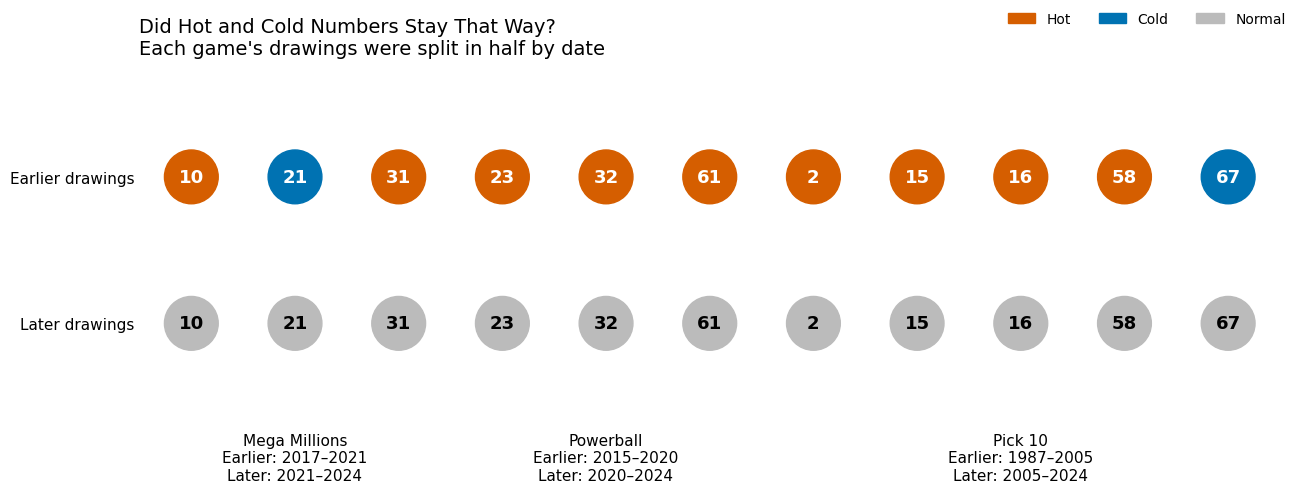

In [12]:
# Find numbers that were hot or cold in earlier drawings, and check them in later drawings

def half_status(h, game):
    counts = h.groupby("Number").size().reindex(range(1, pool[game] + 1), fill_value=0)
    n, p = h["Draw Date"].nunique(), picks[game] / pool[game]
    z = (counts - n * p) / np.sqrt(n * p * (1 - p))
    return np.select([z >= 2, z <= -2], ["Hot", "Cold"], default="Normal")

rows, periods = [], {}
for game, df in current.groupby("Game", sort=False):
    mid = df["Draw Date"].sort_values().unique()[df["Draw Date"].nunique() // 2]
    start, mid_year, end = df["Year"].min(), pd.Timestamp(mid).year, df["Year"].max()
    periods[game] = f"{game}\nEarlier: {start}–{mid_year}\nLater: {mid_year}–{end}"
    first = half_status(df[df["Draw Date"] < mid], game)
    second = half_status(df[df["Draw Date"] >= mid], game)
    rows += [(game, num, f, s) for num, f, s in zip(range(1, pool[game] + 1), first, second) if f != "Normal"]

halves = pd.DataFrame(rows, columns=["Game", "Number", "First Half", "Second Half"])

# Icon array: top row = earlier drawings, bottom row = same numbers in later drawings
colors = {"Hot": "#D55E00", "Cold": "#0072B2", "Normal": "#BBBBBB"}
fig, ax = plt.subplots(figsize=(13, 5))

for row, col in [(1, "First Half"), (0, "Second Half")]:
    ax.scatter(halves.index, [row] * len(halves), s=1500, color=halves[col].map(colors))
    for i, (num, status) in enumerate(zip(halves["Number"], halves[col])):
        ax.text(i, row, num, ha="center", va="center", fontsize=13, fontweight="bold",
                color="black" if status == "Normal" else "white")

ax.set(yticks=[0, 1], yticklabels=["Later drawings", "Earlier drawings"], ylim=(-0.6, 1.6), xticks=[])

# Game name and date periods under each group
for game, idx in halves.groupby("Game", sort=False).groups.items():
    ax.text(idx.to_series().mean(), -0.75, periods[game], ha="center", va="top", fontsize=11)

ax.tick_params(length=0, labelsize=11)
for s in ax.spines.values():
    s.set_visible(False)

fig.legend(handles=[Patch(color=c, label=s) for s, c in colors.items()],
           loc="upper right", ncol=3, frameon=False)
ax.set_title("Did Hot and Cold Numbers Stay That Way?\n"
             "Each game's drawings were split in half by date", fontsize=14, loc="left", pad=25)
plt.tight_layout()
plt.show()

### Assessment - Visual 4

- Each game's drawings were split in half by date, and numbers were labeled hot or cold within each half using the same 2-standard-deviation rule. Eleven numbers were hot or cold in the earlier drawings:
  - **Mega Millions (2017–2021):** Hot numbers were 10 and 31. Cold number was 21.
  - **Powerball (2015–2020):** Hot numbers were 23, 32, and 61.
  - **Pick 10 (1987–2005):** Hot numbers were 2, 15, 16, and 58. Cold number was 67.
- None of the 11 numbers remained hot or cold in the later drawings. All returned to the normal range, and the closest any came to the cutoff was Powerball's 61 at 1.84 standard deviations.
- Being hot or cold in the past did not predict future results. Each drawing is independent, so a number's history provides no advantage in future drawings.
- This supports the earlier findings: the hot and cold numbers reflect short-term random variation rather than a lasting bias in the drawings.

### Summary Assessment - Data Visualization

- **Visual 1 (Donut Chart):** Pick 10 accounted for 97.0% of the numbers in our filtered data because of its longer history, greater number of drawings, and 20 numbers selected per drawing. This reinforced the importance of analyzing each lottery separately to prevent Pick 10 from overwhelming the results.
- **Visual 2 (Polar Wheel):** Most numbers in all three lotteries stayed close to their expected frequencies. Only 10 of 219 numbers crossed the hot or cold thresholds, and they were scattered across the number ranges rather than concentrated in one area.
- **Visual 3 (Swarm Plot):** The spread of z-scores was consistent with what a fair drawing would produce. Approximately 66.7% of numbers fell within 1 standard deviation and 95.4% within 2. All hot and cold numbers fell between 2 and 3 standard deviations from expected, with none reaching more extreme values.
- **Visual 4 (Icon Array):** None of the 11 numbers identified as hot or cold in earlier drawings maintained that classification in later drawings. This suggests that unusual frequencies did not persist across the two periods, and historical patterns offered no reliable indication of future results.

**Overall conclusion**

Together, the four visualizations and chi-square tests tell a consistent story. Hot and cold numbers do exist in the historical data, but their frequencies are consistent with random variation rather than convincing evidence of bias. The number of exceptions was approximately what chance would produce, most remained relatively close to the expected range, and earlier patterns did not persist in later drawings. Although these findings cannot prove that lottery drawings are completely random, they illustrate why apparent patterns should be interpreted cautiously. For lottery players, choosing historically hot numbers or avoiding cold numbers does not improve the odds of winning in a fair drawing.